# Page Turners
## What Makes a Book Loved by Readers?

This project explores relationships between book ratings, popularity, genres, authors, and publication years.

## 1. Research Questions

1. How do average ratings differ across genres?
2. How are publication years associated with ratings?
3. Are more frequently rated books also rated more highly?
4. How do ratings vary across an author's published works?
5. Which books combine high ratings with many ratings?

## 2. Data Loading

The notebook imports reusable functions from the src folder.

In [2]:
import pandas as pd

from src.data_loading import load_csv, PROJECT_ROOT

books = load_csv("books.csv")
ratings = load_csv("ratings.csv")
tags = load_csv("tags.csv")
book_tags = load_csv("book_tags.csv")

books.head()

,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


## 3. Initial Data Exploration

In [3]:
books.shape

(10000, 23)

In [4]:
books.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   book_id                    10000 non-null  int64  
 1   goodreads_book_id          10000 non-null  int64  
 2   best_book_id               10000 non-null  int64  
 3   work_id                    10000 non-null  int64  
 4   books_count                10000 non-null  int64  
 5   isbn                       9300 non-null   str    
 6   isbn13                     9415 non-null   float64
 7   authors                    10000 non-null  str    
 8   original_publication_year  9979 non-null   float64
 9   original_title             9415 non-null   str    
 10  title                      10000 non-null  str    
 11  language_code              8916 non-null   str    
 12  average_rating             10000 non-null  float64
 13  ratings_count              10000 non-null  int64  
 14  wo

In [5]:
books.isna().sum().sort_values(ascending=False)

language_code                1084
isbn                          700
isbn13                        585
original_title                585
original_publication_year      21
work_ratings_count              0
image_url                       0
ratings_5                       0
ratings_4                       0
ratings_3                       0
ratings_2                       0
ratings_1                       0
work_text_reviews_count         0
book_id                         0
ratings_count                   0
average_rating                  0
goodreads_book_id               0
title                           0
authors                         0
books_count                     0
work_id                         0
best_book_id                    0
small_image_url                 0
dtype: int64

## 4. Data Dictionary

The following table describes the main variables used in the project.

| Dataset | Variable | Description |
|---|---|---|
| books, ratings | book_id | Internal book identifier used to connect books and individual ratings. |
| books, book_tags | goodreads_book_id | Goodreads book-edition identifier used to connect books and tags. |
| books | title | Book title. |
| books | authors | Authors and other contributors listed in the metadata. |
| books | original_publication_year | Original publication year recorded in the dataset. |
| books | average_rating | Average rating supplied in the Goodreads metadata. |
| books | ratings_count | Rating count supplied in the book metadata. |
| ratings | user_id | Identifier of the user who submitted a rating. |
| ratings | rating | Individual user rating, from 1 to 5. |
| tags, book_tags | tag_id | Identifier used to connect tags with book-tag records. |
| tags | tag_name | Name of a user-defined tag or shelf. |
| book_tags | count | Frequency associated with a book-tag assignment in the source data. |

### Relationships between the tables

- `ratings.book_id` connects to `books.book_id`.
- `book_tags.goodreads_book_id` connects to `books.goodreads_book_id`.
- `book_tags.tag_id` connects to `tags.tag_id`.

### Initial analytical definitions

Popularity will initially be represented by `ratings_count`.
Reader appreciation will be represented by `average_rating`.

These metadata summaries are kept separate from statistics calculated
directly from the individual observations in `ratings.csv`.

Tags are user-defined shelves and do not always represent literary genres.
Genre analysis will therefore require an explicit tag-selection method.

Source: [goodbooks-10k documentation](https://github.com/zygmuntz/goodbooks-10k)

In [6]:
dataset_overview = pd.DataFrame({
    "dataset": ["books", "ratings", "tags", "book_tags"],
    "rows": [
        books.shape[0],
        ratings.shape[0],
        tags.shape[0],
        book_tags.shape[0],
    ],
    "columns": [
        books.shape[1],
        ratings.shape[1],
        tags.shape[1],
        book_tags.shape[1],
    ],
})

dataset_overview

,dataset,rows,columns
0,books,10000,23
1,ratings,5976479,3
2,tags,34252,2
3,book_tags,999912,3


In [7]:
#per visualizzare i nomi delle colonne 
datasets = {
    "books": books,
    "ratings": ratings,
    "tags": tags,
    "book_tags": book_tags,
}

for name, dataframe in datasets.items():
    print(f"\n{name.upper()}")
    print(dataframe.columns.tolist())


BOOKS
['book_id', 'goodreads_book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url']

RATINGS
['user_id', 'book_id', 'rating']

TAGS
['tag_id', 'tag_name']

BOOK_TAGS
['goodreads_book_id', 'tag_id', 'count']


In [8]:
#esporto tabella di riepilogo
output_path = PROJECT_ROOT / "outputs" / "tables" / "dataset_overview.csv"

output_path.parent.mkdir(parents=True, exist_ok=True)

dataset_overview.to_csv(output_path, index=False)

print(f"Table saved to: {output_path}")

Table saved to: /Users/sofiagolla/page-turners/outputs/tables/dataset_overview.csv


## 5. Data Cleaning

### 5.1 Initial quality checks

Before cleaning the data, we check for missing values, duplicate
identifiers, blank text fields, and potentially invalid numerical values.

These checks do not modify the original dataset.

Cleaning decisions will be based on the results rather than on
automatically dropping every row containing a missing value.

In [9]:
from src.data_cleaning import check_books_quality

quality_report = check_books_quality(books)

quality_report

,check,count
0,total_rows,10000
1,exact_duplicate_rows,0
2,missing_book_ids,0
3,extra_duplicate_book_ids,0
4,missing_goodreads_book_ids,0
5,extra_duplicate_goodreads_book_ids,0
6,missing_or_blank_titles,0
7,missing_or_blank_authors,0
8,missing_or_non_numeric_years,21
9,non_positive_years_to_review,31


In [10]:
from src.data_loading import PROJECT_ROOT

quality_report_path = (
    PROJECT_ROOT / "outputs" / "tables" / "books_quality_report.csv"
)

quality_report_path.parent.mkdir(parents=True, exist_ok=True)

quality_report.to_csv(quality_report_path, index=False)

print(f"Quality report saved to: {quality_report_path}")

Quality report saved to: /Users/sofiagolla/page-turners/outputs/tables/books_quality_report.csv


In [11]:
import pandas as pd

original_years = books["original_publication_year"]

numeric_years = pd.to_numeric(original_years, errors="coerce")

year_details = pd.DataFrame({
    "check": [
        "missing_original_years",
        "non_numeric_years",
        "negative_years",
        "zero_years",
        "non_integer_numeric_years",
    ],
    "count": [
        original_years.isna().sum(),
        (original_years.notna() & numeric_years.isna()).sum(),
        numeric_years.lt(0).sum(),
        numeric_years.eq(0).sum(),
        (
            numeric_years.notna()
            & numeric_years.mod(1).ne(0)
        ).sum(),
    ],
})

year_details

,check,count
0,missing_original_years,21
1,non_numeric_years,0
2,negative_years,31
3,zero_years,0
4,non_integer_numeric_years,0


In [12]:
#visualizza i 31 libri segnalati
columns_to_review = [
    "book_id",
    "title",
    "authors",
    "original_publication_year",
]

year_review = books.loc[
    numeric_years.le(0),
    columns_to_review,
].copy()

year_review["numeric_year"] = numeric_years.loc[year_review.index]

year_review = year_review.sort_values("numeric_year")

year_review

,book_id,title,authors,original_publication_year,numeric_year
2075,2076,The Epic of Gilgamesh,"Anonymous, N.K. Sandars",-1750.0,-1750.0
2141,2142,The Iliad/The Odyssey,"Homer, Robert Fagles, Bernard Knox",-762.0,-762.0
340,341,The Iliad,"Homer, Robert Fagles, Frédéric Mugler, Bernard...",-750.0,-750.0
6165,6166,The I Ching or Book of Changes,"Anonymous, Richard Wilhelm, Cary F. Baynes, C....",-750.0,-750.0
78,79,The Odyssey,"Homer, Robert Fagles, E.V. Rieu, Frédéric Mugl...",-720.0,-720.0
1119,1120,Aesop's Fables,"Aesop, Laura Harris, Laura Gibbs",-560.0,-560.0
5636,5637,The Dhammapada,"Anonymous, Ananda Maitreya, Thich Nhat Hanh, B...",-500.0,-500.0
9678,9679,The Upanishads: Translations from the Sanskrit,"Anonymous, Juan Mascaró",-500.0,-500.0
402,403,The Art of War,"Sun Tzu, Thomas Cleary",-500.0,-500.0
7777,7778,The Analects,"Confucius, D.C. Lau",-476.0,-476.0


### 5.2 Publication-year review

The initial quality report identified 21 books with missing or
non-numeric publication years and 31 books with non-positive years.

Books with unavailable publication years will remain in the main
dataset. They will be excluded only from analyses that require a
known publication year. No publication years will be imputed.

Non-positive years are reviewed separately. Negative values are not
automatically treated as errors because they may represent dates
before the Common Era. Any zero values require further investigation.

This review preserves the original data and distinguishes data-quality
decisions from the selection of books for a particular analysis.

In [13]:
import importlib
import pandas as pd

import src.data_cleaning as data_cleaning

importlib.reload(data_cleaning)

books_before_cleaning = books.copy()

books_clean = data_cleaning.clean_books(books)

# Check that the original dataset has not been modified.
pd.testing.assert_frame_equal(books, books_before_cleaning)

# Check that all books are retained in the same order.
assert books_clean["book_id"].equals(books["book_id"])

books_clean[
    [
        "title",
        "original_publication_year",
        "publication_year",
        "publication_year_missing",
        "is_bce",
    ]
].head()

,title,original_publication_year,publication_year,publication_year_missing,is_bce
0,"The Hunger Games (The Hunger Games, #1)",2008.0,2008,False,False
1,Harry Potter and the Sorcerer's Stone (Harry P...,1997.0,1997,False,False
2,"Twilight (Twilight, #1)",2005.0,2005,False,False
3,To Kill a Mockingbird,1960.0,1960,False,False
4,The Great Gatsby,1925.0,1925,False,False


In [14]:
cleaning_summary = pd.DataFrame({
    "check": [
        "books_before_cleaning",
        "books_after_cleaning",
        "missing_publication_years",
        "negative_publication_years",
        "zero_publication_years",
        "books_with_recorded_year",
    ],
    "count": [
        len(books),
        len(books_clean),
        books_clean["publication_year"].isna().sum(),
        books_clean["publication_year"].lt(0).sum(),
        books_clean["publication_year"].eq(0).sum(),
        books_clean["publication_year"].notna().sum(),
    ],
})

cleaning_summary

,check,count
0,books_before_cleaning,10000
1,books_after_cleaning,10000
2,missing_publication_years,21
3,negative_publication_years,31
4,zero_publication_years,0
5,books_with_recorded_year,9979


### 5.3 Cleaning decisions and prepared variables

All 10,000 books are retained in the prepared dataset.

The 21 missing publication years remain missing. No publication dates
are imputed. These books will be excluded only from analyses that
require an available publication year.

The 31 negative publication years are preserved as recorded in the
source metadata and flagged as BCE entries. Reviewing the titles
supports this interpretation, but does not independently verify the
historical accuracy of each date.

The original `original_publication_year` column is preserved.
A new nullable-integer column, `publication_year`, is used for analysis.

Two additional variables are created:

- `publication_year_missing`: indicates whether the year is unavailable.
- `is_bce`: indicates a negative recorded year, remaining missing when
  the publication year is unknown.

Leading and trailing whitespace is removed from titles and author fields.
Ratings, rating counts, identifiers, and row order are preserved.

The cleaning function operates on a copy and leaves the original
`books` DataFrame unchanged.

In [15]:
from src.data_loading import PROJECT_ROOT

processed_dir = PROJECT_ROOT / "data" / "processed"
tables_dir = PROJECT_ROOT / "outputs" / "tables"

processed_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

books_clean.to_csv(
    processed_dir / "books_clean.csv",
    index=False,
)

cleaning_summary.to_csv(
    tables_dir / "books_cleaning_summary.csv",
    index=False,
)

print("Saved: data/processed/books_clean.csv")
print("Saved: outputs/tables/books_cleaning_summary.csv")

Saved: data/processed/books_clean.csv
Saved: outputs/tables/books_cleaning_summary.csv


## 6. Data Preparation and Merging
`books_tags`: one row per source book-tag record, including
   the tag name and selected book metadata.

Repeated book-tag pairs are preserved and flagged in
`repeated_book_tag_pair`. Therefore, this intermediate table
does not yet contain one unique row per book-tag pair.

No tag counts are summed or discarded during merging.
Repeated pairs will be resolved before calculating genre-level
statistics.

In [16]:
import importlib
import pandas as pd

import src.data_merging as data_merging

importlib.reload(data_merging)

books_enriched = data_merging.merge_books_ratings(
    books_clean,
    ratings,
)

books_enriched[
    [
        "book_id",
        "title",
        "average_rating",
        "ratings_count",
        "sample_average_rating",
        "sample_ratings_count",
        "ratings_match",
    ]
].head()

,book_id,title,average_rating,ratings_count,sample_average_rating,sample_ratings_count,ratings_match
0,1,"The Hunger Games (The Hunger Games, #1)",4.34,4780653,4.279707,22806,both
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,4.44,4602479,4.351350,21850,both
2,3,"Twilight (Twilight, #1)",3.57,3866839,3.214341,16931,both
3,4,To Kill a Mockingbird,4.25,3198671,4.329369,19088,both
4,5,The Great Gatsby,3.89,2683664,3.772224,16604,both


In [17]:
# collego libri e tag
import importlib

import src.data_merging as data_merging

importlib.reload(data_merging)

books_tags = data_merging.merge_books_tags(
    books_clean,
    book_tags,
    tags,
)

books_tags[
    [
        "book_id",
        "goodreads_book_id",
        "tag_id",
        "tag_name",
        "tag_count",
        "repeated_book_tag_pair",
        "tag_match",
        "book_match",
    ]
].head(10)

,book_id,goodreads_book_id,tag_id,tag_name,tag_count,repeated_book_tag_pair,tag_match,book_match
0,27,1,30574,to-read,167697,False,both,both
1,27,1,11305,fantasy,37174,False,both,both
2,27,1,11557,favorites,34173,False,both,both
3,27,1,8717,currently-reading,12986,False,both,both
4,27,1,33114,young-adult,12716,False,both,both
5,27,1,11743,fiction,9954,False,both,both
6,27,1,14017,harry-potter,7169,False,both,both
7,27,1,5207,books-i-own,6221,False,both,both
8,27,1,22743,owned,4974,False,both,both
9,27,1,32989,ya,4364,False,both,both


In [18]:
#rapporto sui duplicati
pair_columns = ["goodreads_book_id", "tag_id"]

repeated_links = book_tags.loc[
    book_tags.duplicated(pair_columns, keep=False)
].copy()

duplicate_review = (
    repeated_links
    .groupby(pair_columns, as_index=False, dropna=False)
    .agg(
        source_rows=("count", "size"),
        different_counts=(
            "count",
            lambda values: values.nunique(dropna=False),
        ),
        minimum_count=("count", "min"),
        maximum_count=("count", "max"),
    )
)

print("Rows belonging to repeated pairs:", len(repeated_links))
print("Number of repeated pairs:", len(duplicate_review))

duplicate_review.head(20)

Rows belonging to repeated pairs: 16
Number of repeated pairs: 8


,goodreads_book_id,tag_id,source_rows,different_counts,minimum_count,maximum_count
0,3,22743,2,2,6065,6066
1,22369,25148,2,1,4,4
2,52629,2928,2,1,1,1
3,52629,10094,2,1,1,1
4,52629,13272,2,1,1,1
5,52629,13322,2,1,1,1
6,77449,15169,2,2,7,8
7,77449,25148,2,1,7,7


In [19]:
assert len(books_tags) == len(book_tags)

### 6.1 Preparing book–genre memberships

For the first genre comparison, we select seven genres:
Fantasy, Science fiction, Romance, Mystery, Thriller,
Historical fiction, and Horror.

An explicit dictionary maps the original tags to these categories.
The tags `sci-fi` and `science-fiction` are combined into
the same category.

Each book can belong to more than one genre, but each
book–genre combination appears only once.

This analysis uses the presence of a genre label.
Tag counts are not used as weights.

Books without a selected genre tag are excluded only from
this genre comparison. They remain available in the main
book tables for the other analyses.

In [20]:
import importlib
import src.data_cleaning as data_cleaning

importlib.reload(data_cleaning)

assert books_tags["book_match"].eq("both").all()
assert books_tags["tag_match"].eq("both").all()

book_genres = data_cleaning.prepare_book_genres(books_tags)

book_genres.head(10)

,book_id,genre
0,27,Fantasy
1,27,Mystery
2,27,Romance
3,21,Fantasy
4,21,Mystery
5,21,Romance
6,21,Science fiction
7,2,Fantasy
8,2,Mystery
9,18,Fantasy


In [21]:
assert not book_genres.empty

assert not book_genres.duplicated(["book_id", "genre"]).any()

assert book_genres[["book_id", "genre"]].notna().all().all()

classified_books = book_genres["book_id"].nunique()

print(
    f"Books with at least one selected genre: "
    f"{classified_books:,} out of {len(books_clean):,}"
)

genre_counts = (
    book_genres
    .groupby("genre")["book_id"]
    .nunique()
    .sort_values(ascending=False)
)

genre_counts

Books with at least one selected genre: 8,392 out of 10,000


genre
Fantasy               4259
Romance               4251
Mystery               3686
Historical fiction    2590
Thriller              2522
Science fiction       2471
Horror                1372
Name: book_id, dtype: int64

## 7. Genre Analysis

This section compares book-level average ratings across
the selected genre labels.

Each book contributes once within each genre.
A book associated with several genres contributes to
each of those categories.

The comparison uses `average_rating` from the Goodreads
book metadata. Each book receives equal weight within
its genre.

The summary reports the number of books, the mean,
the median, and the standard deviation of book-level
average ratings.

In [22]:
import importlib
import src.data_merging as data_merging

importlib.reload(data_merging)

books_by_genre = data_merging.merge_books_genres(
    books_enriched,
    book_genres,
)

assert len(books_by_genre) == len(book_genres)

books_by_genre.head(10)

,book_id,genre,title,average_rating,ratings_count
0,27,Fantasy,Harry Potter and the Half-Blood Prince (Harry ...,4.54,1678823
1,27,Mystery,Harry Potter and the Half-Blood Prince (Harry ...,4.54,1678823
2,27,Romance,Harry Potter and the Half-Blood Prince (Harry ...,4.54,1678823
3,21,Fantasy,Harry Potter and the Order of the Phoenix (Har...,4.46,1735368
4,21,Mystery,Harry Potter and the Order of the Phoenix (Har...,4.46,1735368
5,21,Romance,Harry Potter and the Order of the Phoenix (Har...,4.46,1735368
6,21,Science fiction,Harry Potter and the Order of the Phoenix (Har...,4.46,1735368
7,2,Fantasy,Harry Potter and the Sorcerer's Stone (Harry P...,4.44,4602479
8,2,Mystery,Harry Potter and the Sorcerer's Stone (Harry P...,4.44,4602479
9,18,Fantasy,Harry Potter and the Prisoner of Azkaban (Harr...,4.53,1832823


In [23]:
assert len(books_by_genre) == len(book_genres)

In [24]:
import src.analysis as analysis

importlib.reload(analysis)

genre_summary = analysis.summarize_genres(
    books_by_genre
)

genre_summary.round(3)

,genre,n_books,mean_rating,median_rating,std_rating
0,Fantasy,4259,4.058,4.07,0.249
1,Science fiction,2471,4.036,4.05,0.240
2,Romance,4251,3.999,4.02,0.266
3,Horror,1372,3.988,3.99,0.258
4,Mystery,3686,3.983,3.99,0.242
5,Thriller,2522,3.969,3.98,0.240
6,Historical fiction,2590,3.966,3.98,0.247


## 8. Publication Year Analysis

This section investigates how book-level average ratings
differ across original publication periods.

The analysis uses one row per book and gives each book
equal weight.

Books with missing publication years are excluded only
from this analysis. Books with negative publication years
are retained in a separate BCE category.

Publication periods are exploratory groups with different
durations. The number of books in each group is reported
alongside the rating statistics.

The ratings reflect the dataset snapshot. The publication
year refers to when the book was originally published.

In [25]:
import importlib
import src.data_cleaning as data_cleaning

importlib.reload(data_cleaning)

books_by_period = data_cleaning.prepare_publication_periods(
    books_enriched
)

assert books_by_period["book_id"].is_unique
assert books_by_period["publication_period"].notna().all()

excluded_books = len(books_enriched) - len(books_by_period)

print(f"Books included: {len(books_by_period):,}")
print(f"Books excluded for missing year: {excluded_books:,}")

print(
    "Earliest recorded publication year:",
    books_by_period["publication_year"].min(),
)

print(
    "Latest recorded publication year:",
    books_by_period["publication_year"].max(),
)

books_by_period[
    [
        "title",
        "publication_year",
        "publication_period",
    ]
].head(10)

Books included: 9,979
Books excluded for missing year: 21
Earliest recorded publication year: -1750
Latest recorded publication year: 2017


,title,publication_year,publication_period
0,"The Hunger Games (The Hunger Games, #1)",2008,2000–2009
1,Harry Potter and the Sorcerer's Stone (Harry P...,1997,1950–1999
2,"Twilight (Twilight, #1)",2005,2000–2009
3,To Kill a Mockingbird,1960,1950–1999
4,The Great Gatsby,1925,1900–1949
5,The Fault in Our Stars,2012,2010+
6,The Hobbit,1937,1900–1949
7,The Catcher in the Rye,1951,1950–1999
8,"Angels & Demons (Robert Langdon, #1)",2000,2000–2009
9,Pride and Prejudice,1813,1800–1899


In [26]:
import src.analysis as analysis

importlib.reload(analysis)

publication_summary = (
    analysis.summarize_publication_periods(
        books_by_period
    )
)

assert (
    publication_summary["n_books"].sum()
    == len(books_by_period)
)

publication_summary.round(3)

,publication_period,n_books,mean_rating,median_rating,std_rating
0,BCE,31,3.946,3.950,0.179
1,1–1799,94,3.892,3.865,0.257
2,1800–1899,254,3.958,3.970,0.213
3,1900–1949,466,4.033,4.060,0.216
4,1950–1999,2946,4.034,4.050,0.221
5,2000–2009,3121,3.977,3.990,0.265
6,2010+,3067,3.999,4.020,0.277


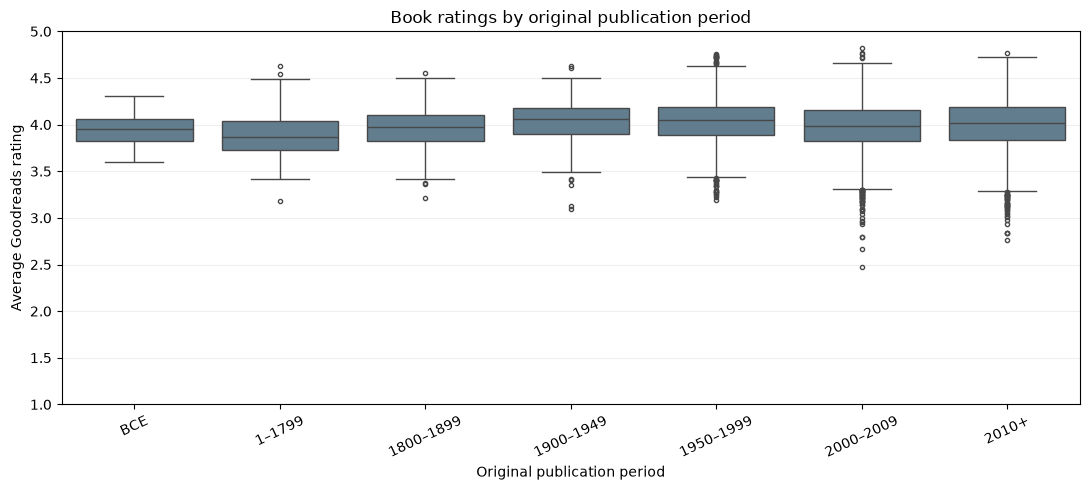

In [27]:
import matplotlib.pyplot as plt
import src.visualization as visualization

importlib.reload(visualization)

publication_figure = (
    visualization.plot_ratings_by_publication_period(
        books_by_period
    )
)

plt.show()

### 8.1 Interpretation

The median book rating is close to four stars across all
publication periods. The 1900–1949 and 1950–1999 groups
appear to have slightly higher median ratings, while
the 1–1799 group has a lower median.

However, the central distributions overlap substantially.
The plot does not show a consistent increase or decrease
in ratings from older to newer publication periods.

These observations describe differences in book-level
average ratings within this dataset. They do not establish
that publication period causes differences in reader
appreciation.

The publication periods have different durations.
The number of books in each group should also be considered
when interpreting the comparison.

In [28]:
from src.data_loading import PROJECT_ROOT

tables_dir = PROJECT_ROOT / "outputs" / "tables"
figures_dir = PROJECT_ROOT / "outputs" / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

publication_summary.to_csv(
    tables_dir / "publication_period_summary.csv",
    index=False,
)

publication_figure.savefig(
    figures_dir / "ratings_by_publication_period.png",
    dpi=300,
    bbox_inches="tight",
)

print("Saved: outputs/tables/publication_period_summary.csv")
print("Saved: outputs/figures/ratings_by_publication_period.png")

Saved: outputs/tables/publication_period_summary.csv
Saved: outputs/figures/ratings_by_publication_period.png


In [29]:
print(
    publication_summary.round(3).to_string(index=False)
)

publication_period  n_books  mean_rating  median_rating  std_rating
               BCE       31        3.946          3.950       0.179
            1–1799       94        3.892          3.865       0.257
         1800–1899      254        3.958          3.970       0.213
         1900–1949      466        4.033          4.060       0.216
         1950–1999     2946        4.034          4.050       0.221
         2000–2009     3121        3.977          3.990       0.265
             2010+     3067        3.999          4.020       0.277


### 8.1 Interpretation

The analysis includes 9,979 books with a known original
publication year. The remaining 21 books are excluded
from this comparison only.

Mean book ratings range from 3.892 for the 1–1799 group
to 4.034 for the 1950–1999 group, a difference of 0.142
rating points. The 1900–1949 group has an almost identical
mean of 4.033 and the highest median rating, at 4.060.

The results do not show a consistent increase or decrease
in ratings across publication periods. For example, the
mean decreases from 4.034 in 1950–1999 to 3.977 in
2000–2009, before increasing slightly to 3.999 in 2010+.
The boxplot also shows substantial overlap between the
central rating distributions.

The two most recent groups have the largest standard
deviations: 0.265 for 2000–2009 and 0.277 for 2010+.
These values describe variation in book-level average
ratings within each publication period.

Group sizes are highly unequal. The BCE group contains
31 books, while each of the two most recent groups
contains more than 3,000. The publication periods also
cover different lengths of time.

These findings describe the books represented in the
dataset and do not establish that publication period
causes differences in reader appreciation. The comparison
uses ratings from the dataset snapshot; it does not
track how the rating of an individual book changes
as the book gets older.


## 9. Author Analysis

This section compares book-level average ratings across
authors and examines how ratings differ between books
published at different points in an author's bibliography.

Books are assigned to the first name listed in the authors
column. This is an operational attribution rule: it does
not establish the role of every listed contributor.

Each book contributes once and receives equal weight
in the author-level summary.

Books with missing publication years remain in the overall
author summary. They are excluded only from the
publication-year comparison.

In [30]:
import importlib
import src.data_cleaning as data_cleaning

importlib.reload(data_cleaning)

books_by_author = data_cleaning.prepare_book_authors(
    books_enriched
)

assert books_by_author["book_id"].is_unique
assert books_by_author["first_listed_author"].notna().all()

excluded_books = len(books_enriched) - len(books_by_author)

print(f"Books included: {len(books_by_author):,}")
print(f"Books excluded for missing author: {excluded_books:,}")

books_by_author[
    ["book_id", "authors", "first_listed_author"]
].head(10)

Books included: 10,000
Books excluded for missing author: 0


,book_id,authors,first_listed_author
0,1,Suzanne Collins,Suzanne Collins
1,2,"J.K. Rowling, Mary GrandPré",J.K. Rowling
2,3,Stephenie Meyer,Stephenie Meyer
3,4,Harper Lee,Harper Lee
4,5,F. Scott Fitzgerald,F. Scott Fitzgerald
5,6,John Green,John Green
6,7,J.R.R. Tolkien,J.R.R. Tolkien
7,8,J.D. Salinger,J.D. Salinger
8,9,Dan Brown,Dan Brown
9,10,Jane Austen,Jane Austen


In [31]:
import src.analysis as analysis

importlib.reload(analysis)

author_summary = analysis.summarize_authors(
    books_by_author
)

assert author_summary["n_books"].sum() == len(books_by_author)

author_summary.head(10).round(3)

,first_listed_author,n_books,n_books_with_year,n_publication_years,mean_rating,median_rating,std_rating
0,James Patterson,98,98,24,3.932,3.980,0.162
1,Stephen King,80,80,40,3.971,3.925,0.301
2,Nora Roberts,62,62,23,4.075,4.095,0.093
3,Dean Koontz,52,52,33,3.862,3.860,0.172
4,Terry Pratchett,48,48,29,4.131,4.175,0.191
5,Agatha Christie,42,42,34,3.883,3.870,0.143
6,J.D. Robb,41,41,22,4.311,4.310,0.055
7,Janet Evanovich,37,37,22,3.937,3.930,0.199
8,Meg Cabot,37,37,13,3.804,3.770,0.193
9,David Baldacci,34,34,21,4.019,4.035,0.134


### 9.1 Selected Authors Across Publication Years

The publication-year comparison includes up to three authors
with at least five dated books and at least two distinct
publication years.

Eligible authors are selected by the number of dated books
represented in the dataset, with alphabetical tie-breaking.

The five-book threshold is an exploratory choice.
Selection is based on data availability and does not use
the rating values.

In [32]:
importlib.reload(analysis)

author_timeline = analysis.prepare_author_timeline(
    books_by_author,
    min_books=5,
    n_authors=3,
)

assert author_timeline["book_id"].is_unique
assert author_timeline["publication_year"].notna().all()

selected_author_summary = author_summary.loc[
    author_summary["first_listed_author"].isin(
        author_timeline["first_listed_author"]
    )
].copy()

selected_author_summary.round(3)

,first_listed_author,n_books,n_books_with_year,n_publication_years,mean_rating,median_rating,std_rating
0,James Patterson,98,98,24,3.932,3.980,0.162
1,Stephen King,80,80,40,3.971,3.925,0.301
2,Nora Roberts,62,62,23,4.075,4.095,0.093


In [33]:
author_timeline.groupby(
    "first_listed_author",
    sort=False,
).head(5)[
    [
        "first_listed_author",
        "publication_year",
        "title",
        "average_rating",
    ]
]

,first_listed_author,publication_year,title,average_rating
0,James Patterson,1980,Cradle and All,3.87
1,James Patterson,1993,"Along Came a Spider (Alex Cross, #1)",4.08
2,James Patterson,1995,"Kiss the Girls (Alex Cross, #2)",3.93
3,James Patterson,1995,Hide and Seek,4.10
4,James Patterson,1996,"Jack & Jill (Alex Cross, #3)",3.95
98,Nora Roberts,1994,"Born in Fire (Born In Trilogy, #1)",4.21
99,Nora Roberts,1994,Hidden Riches,3.97
100,Nora Roberts,1995,"Born in Ice (Born In Trilogy, #2)",4.13
101,Nora Roberts,1996,Montana Sky,4.07
102,Nora Roberts,1996,"Born in Shame (Born In Trilogy, #3)",4.07


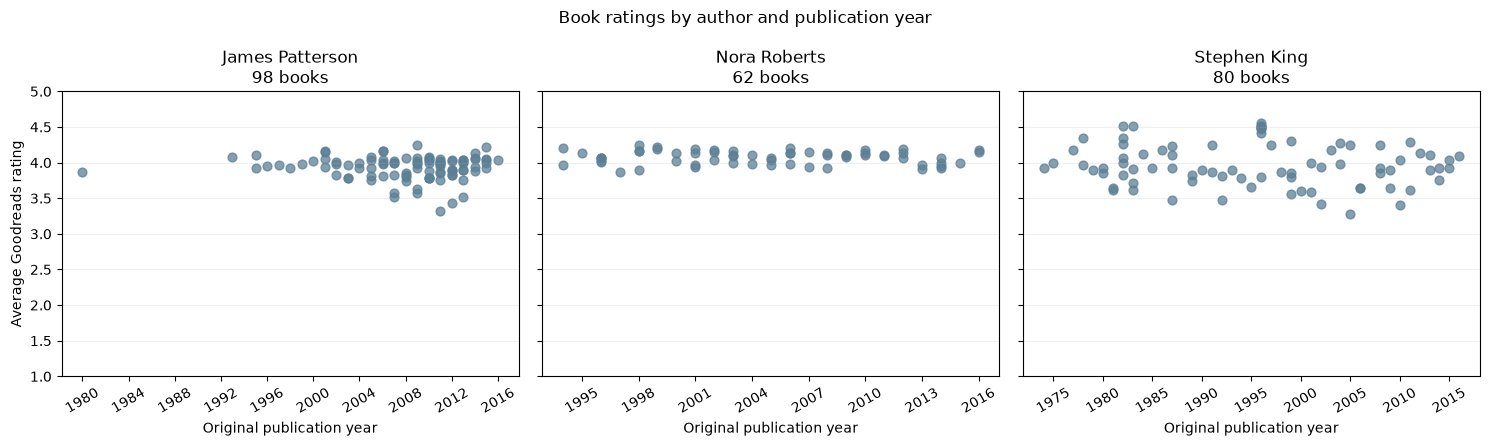

In [34]:
import matplotlib.pyplot as plt
import src.visualization as visualization

importlib.reload(visualization)

author_figure = visualization.plot_author_ratings_by_year(
    author_timeline
)

plt.show()

In [35]:
from src.data_loading import PROJECT_ROOT

tables_dir = PROJECT_ROOT / "outputs" / "tables"
figures_dir = PROJECT_ROOT / "outputs" / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

author_summary.to_csv(
    tables_dir / "author_summary.csv",
    index=False,
)

author_timeline.to_csv(
    tables_dir / "author_timeline.csv",
    index=False,
)

author_figure.savefig(
    figures_dir / "author_ratings_by_year.png",
    dpi=300,
    bbox_inches="tight",
)

print("Saved: outputs/tables/author_summary.csv")
print("Saved: outputs/tables/author_timeline.csv")
print("Saved: outputs/figures/author_ratings_by_year.png")

Saved: outputs/tables/author_summary.csv
Saved: outputs/tables/author_timeline.csv
Saved: outputs/figures/author_ratings_by_year.png


### 9.2 Scope and Limitations

The author summaries describe the books represented
in this dataset. They do not necessarily cover each
author's complete bibliography.

Attribution uses the first listed name. Coauthorship
and other contributor roles are not fully represented
by this rule. Name variants and pseudonyms are not
automatically combined.

Collections and other multi-work records, where present,
remain included as distinct book records.

The scatterplots compare the available average ratings
of books with different original publication years.
They do not measure how an individual book's rating
changes over time.

### 9.3 Interpretation

The comparison includes 98 books attributed to James Patterson,
80 to Stephen King, and 62 to Nora Roberts. All 240 books have
a recorded publication year and are included in the plots.

Among these three selected authors, Nora Roberts has the
highest mean rating, at 4.075, and the highest median,
at 4.095. Her books also have the lowest standard deviation,
at 0.093, indicating less variation between their average
ratings.

Stephen King's books have the highest standard deviation,
at 0.301, while James Patterson's have an intermediate
standard deviation of 0.162. This supports the visual
observation that the ratings of King's books are more
widely dispersed.

Stephen King's mean rating of 3.971 is slightly higher
than James Patterson's mean of 3.932. However, Patterson
has the higher median: 3.980 compared with 3.925.
This illustrates why both mean and median are useful
when comparing rating distributions.

The difference between the highest and lowest author-level
means is 0.143 rating points. Each book receives equal
weight in these calculations.

The publication-year plots do not show a simple,
consistently increasing or decreasing pattern for these
authors. They compare different books using ratings
available in the dataset snapshot.

These conclusions apply to the represented books of the
three selected authors. The authors were selected by the
number of dated books available, without using their
rating values.

In [36]:
print(
    selected_author_summary.round(3).to_string(index=False)
)

first_listed_author  n_books  n_books_with_year  n_publication_years  mean_rating  median_rating  std_rating
    James Patterson       98                 98                   24        3.932          3.980       0.162
       Stephen King       80                 80                   40        3.971          3.925       0.301
       Nora Roberts       62                 62                   23        4.075          4.095       0.093


## 10. Popularity versus Appreciation

This section investigates whether books with more ratings
also tend to have higher average ratings.

Popularity is measured using ratings_count, while reader
appreciation is measured using average_rating. Both variables
come from the book metadata.

The analysis uses one row per book. A scatterplot shows
the relationship between the two variables, and a summary
table compares ratings across four popularity quartiles.

Books with missing values in either measure or with zero
rating counts are excluded from this comparison.
The number of excluded books is reported.

In [37]:
import importlib
import src.data_cleaning as data_cleaning

importlib.reload(data_cleaning)

books_popularity = data_cleaning.prepare_popularity_data(
    books_enriched
)

assert books_popularity["book_id"].is_unique

assert books_popularity[
    ["ratings_count", "average_rating", "popularity_quartile"]
].notna().all().all()

excluded_books = len(books_enriched) - len(books_popularity)

print(f"Books included: {len(books_popularity):,}")
print(
    "Books excluded for missing metrics or zero ratings: "
    f"{excluded_books:,}"
)
print(
    "Books with zero rating counts in the input:",
    books_enriched["ratings_count"].eq(0).sum(),
)

books_popularity.head(10)

Books included: 10,000
Books excluded for missing metrics or zero ratings: 0
Books with zero rating counts in the input: 0


,book_id,title,ratings_count,average_rating,popularity_quartile
0,1,"The Hunger Games (The Hunger Games, #1)",4780653,4.34,Q4 (highest)
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,4602479,4.44,Q4 (highest)
2,3,"Twilight (Twilight, #1)",3866839,3.57,Q4 (highest)
3,4,To Kill a Mockingbird,3198671,4.25,Q4 (highest)
4,5,The Great Gatsby,2683664,3.89,Q4 (highest)
5,6,The Fault in Our Stars,2346404,4.26,Q4 (highest)
6,7,The Hobbit,2071616,4.25,Q4 (highest)
7,8,The Catcher in the Rye,2044241,3.79,Q4 (highest)
8,9,"Angels & Demons (Robert Langdon, #1)",2001311,3.85,Q4 (highest)
9,10,Pride and Prejudice,2035490,4.24,Q4 (highest)


### 10.1 Ratings by Popularity Quartile

Books are divided into four groups using the distribution
of ratings_count.

Q1 contains the books with the lowest rating counts in
the analysed dataset, while Q4 contains those with the highest.

The summary reports the number of books, the observed
rating-count range, and the mean, median and standard
deviation of book-level average ratings.

Each book receives equal weight.

In [38]:
import src.analysis as analysis

importlib.reload(analysis)

popularity_summary = analysis.summarize_popularity_quartiles(
    books_popularity
)

assert popularity_summary["n_books"].sum() == len(
    books_popularity
)

popularity_summary.round(3)

,popularity_quartile,n_books,min_ratings_count,max_ratings_count,mean_rating,median_rating,std_rating
0,Q1 (lowest),2500,2716,13568,3.968,3.98,0.271
1,Q2,2500,13569,21154,4.003,4.02,0.254
2,Q3,2500,21157,41052,4.013,4.03,0.248
3,Q4 (highest),2500,41058,4780653,4.025,4.04,0.240


### 10.2 Popularity and Average Rating

The scatterplot shows one point per book.

The horizontal axis uses a logarithmic scale because
rating counts span a wide range. The vertical axis shows
average ratings on the original scale from 1 to 5.

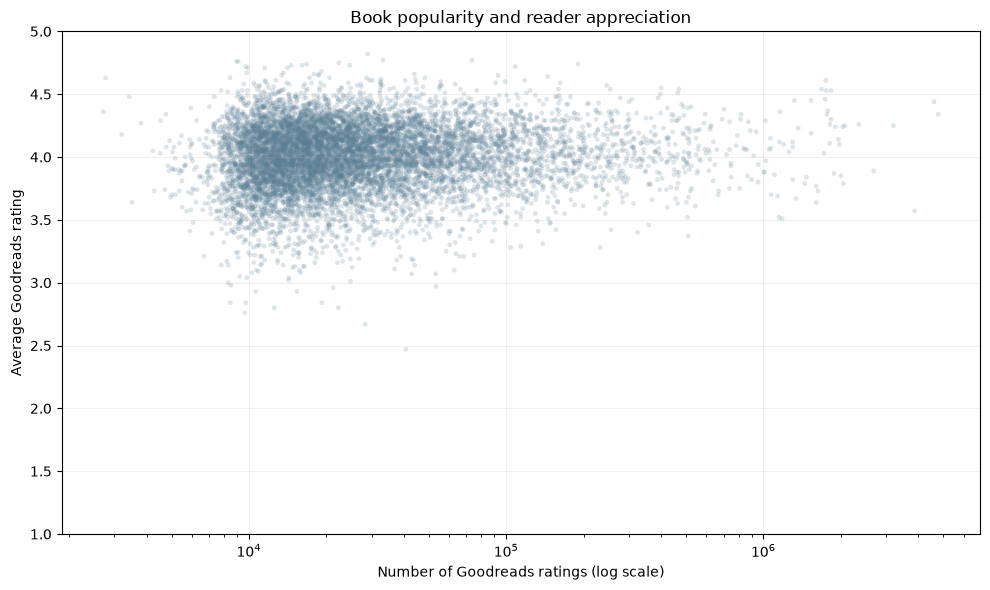

In [39]:
import matplotlib.pyplot as plt
import src.visualization as visualization

importlib.reload(visualization)

popularity_figure = visualization.plot_popularity_vs_appreciation(
    books_popularity
)

plt.show()

In [40]:
from src.data_loading import PROJECT_ROOT

tables_dir = PROJECT_ROOT / "outputs" / "tables"
figures_dir = PROJECT_ROOT / "outputs" / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

popularity_summary.to_csv(
    tables_dir / "popularity_quartile_summary.csv",
    index=False,
)

popularity_figure.savefig(
    figures_dir / "popularity_vs_appreciation.png",
    dpi=300,
    bbox_inches="tight",
)

print("Saved: outputs/tables/popularity_quartile_summary.csv")
print("Saved: outputs/figures/popularity_vs_appreciation.png")

Saved: outputs/tables/popularity_quartile_summary.csv
Saved: outputs/figures/popularity_vs_appreciation.png


### 10.3 Interpretation

All 10,000 books have usable average ratings and positive
rating counts, so no books are excluded from this analysis.
Each popularity quartile contains 2,500 books.

The mean book rating increases from 3.968 in the lowest
popularity quartile to 4.025 in the highest, a difference
of approximately 0.057 rating points.

Median ratings also increase, from 3.98 in Q1 to 4.04 in Q4.
However, the differences between group averages are small
compared with the variation in ratings between books
within each group.

The scatterplot shows considerable overlap in average
ratings across different popularity levels. Books with
similar numbers of ratings can have substantially
different average ratings.

These results suggest a modest descriptive association
between greater popularity and higher average appreciation
within the dataset. They do not establish a causal
relationship.

The quartiles describe relative popularity among the books
included in goodbooks-10k. Since the dataset already focuses
on highly rated-in-volume books, these findings should not
be generalised to all published books.

## 11. Statistical Analysis

This section quantifies the association between book popularity
and reader appreciation.

Popularity is measured using ratings_count, while appreciation
is measured using average_rating.

### 11.1 Method

We use Spearman's rank correlation to assess whether books
with more ratings tend to receive higher average ratings.

Spearman's correlation measures a monotonic association:
whether higher values of one variable tend to correspond
to higher or lower values of the other.

The analysis uses books_popularity, prepared in Section 10,
with one observation per book.

The coefficient is interpreted descriptively for the books
included in this dataset.

In [45]:
import importlib
import src.analysis as analysis

importlib.reload(analysis)

popularity_correlation = (
    analysis.calculate_popularity_correlation(
        books_popularity
    )
)

assert popularity_correlation.loc[0, "n_books"] == len(
    books_popularity
)

assert (
    -1
    <= popularity_correlation.loc[0, "spearman_rho"]
    <= 1
)

popularity_correlation.round(4)

,method,n_books,spearman_rho
0,Spearman,10000,0.0792


### 11.2 Results and Interpretation

The Spearman correlation between ratings_count and average_rating
is approximately 0.079, calculated across 10,000 books.

This indicates a very weak positive monotonic association.
Books with more ratings show only a slight overall tendency
to receive higher average ratings.

This result is consistent with the small differences between
popularity quartiles observed in Section 10.

The coefficient describes the association between the two
variables. It should not be interpreted as a percentage
of explained variation.

A weak Spearman correlation does not rule out other patterns,
such as non-monotonic relationships or differences between
subgroups.

The analysis is descriptive and does not establish causality.
It also does not account for other factors, such as author,
genre or publication year.

The findings apply to the books included in goodbooks-10k.
Since the dataset focuses on books with many ratings,
the result should not be generalised to all published books.

In [46]:
from src.data_loading import PROJECT_ROOT

tables_dir = PROJECT_ROOT / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

correlation_path = (
    tables_dir / "popularity_correlation.csv"
)

popularity_correlation.to_csv(
    correlation_path,
    index=False,
)

print(f"Saved: {correlation_path}")

Saved: /Users/sofiagolla/page-turners/outputs/tables/popularity_correlation.csv


## 12. Main Findings


This section brings together the main findings from the analyses
of genres, publication periods, authors, and book popularity.

Reader appreciation is measured using average_rating.
Popularity is measured using ratings_count.

The findings describe the books included in the dataset.
They identify observed patterns and associations, without
establishing causal relationships.

### 12.1 Genres: Coverage and Average Ratings

The selected genre tags identify at least one genre for
8,392 of the 10,000 books, corresponding to 83.92% of the dataset.

Fantasy and Romance are the most represented categories,
with 4,259 and 4,251 books respectively.

These counts describe how many books are associated with
each selected genre. They do not measure how highly readers
rate those books.

Genre categories overlap: a book can belong to more than
one genre. The remaining 1,608 books are not classified
by the selected tag mapping.

The table below summarises the average ratings of books
associated with each genre.

In [48]:
from IPython.display import Markdown, display

genre_findings = genre_summary.sort_values(
    "mean_rating",
    ascending=False,
)

display(genre_findings.round(3))

highest_mean_genre = genre_findings.iloc[0]
lowest_mean_genre = genre_findings.iloc[-1]

display(
    Markdown(
        "Across the selected genre groups, observed mean ratings "
        f"range from **{lowest_mean_genre['mean_rating']:.3f}** "
        f"for **{lowest_mean_genre['genre']}** "
        f"to **{highest_mean_genre['mean_rating']:.3f}** "
        f"for **{highest_mean_genre['genre']}**."
    )
)

,genre,n_books,mean_rating,median_rating,std_rating
0,Fantasy,4259,4.058,4.07,0.249
1,Science fiction,2471,4.036,4.05,0.240
2,Romance,4251,3.999,4.02,0.266
3,Horror,1372,3.988,3.99,0.258
4,Mystery,3686,3.983,3.99,0.242
5,Thriller,2522,3.969,3.98,0.240
6,Historical fiction,2590,3.966,3.98,0.247


Across the selected genre groups, observed mean ratings range from **3.966** for **Historical fiction** to **4.058** for **Fantasy**.

Each genre mean gives equal weight to the books in that group.

The comparison describes the books associated with the selected
genre tags. Because the categories overlap, the same book may
contribute to more than one group.

A higher group mean does not imply that every book in that
genre receives a high rating. Median ratings and within-group
variation should also be considered when interpreting the
comparison.

### 12.2 Publication Periods: Modest Differences in Average Ratings

The publication-period analysis includes 9,979 books.
The remaining 21 books have no usable publication year
and are excluded from this comparison.

Mean ratings range from 3.892 for books published in 1–1799
to 4.034 for books published in 1950–1999.

Books published in 1900–1949 have a very similar mean rating
of 4.033. The difference between the highest and lowest
period means is approximately 0.142 rating points.

Average ratings do not increase or decrease steadily across
successive publication periods.

These results describe differences between publication groups.
They do not show that a book's age causes readers to rate it
more or less favourably.

### 12.3 Selected Authors: Differences in Average Ratings and Variation

The author comparison focuses on James Patterson,
Stephen King and Nora Roberts, selected according to
the number of books with usable publication years.

| First-listed author | Books | Mean rating | Standard deviation |
|---|---:|---:|---:|
| James Patterson | 98 | 3.932 | 0.162 |
| Stephen King | 80 | 3.971 | 0.301 |
| Nora Roberts | 62 | 4.075 | 0.093 |

Among these three authors, Nora Roberts has the highest
mean rating and the lowest variation in book-level
average ratings.

Stephen King has the greatest variation in average ratings
across the included books.

These findings apply to the selected authors and the books
available in the dataset. They do not represent a ranking
of all authors or an assessment of their complete bibliographies.

The publication-year plots compare different books using
their original publication years. They do not track how
the rating of an individual book changes over time.

### 12.4 Popularity and Appreciation: A Very Weak Positive Association

The popularity analysis includes all 10,000 books,
with 2,500 books in each popularity quartile.

The mean book rating increases from 3.968 in the lowest
popularity quartile to 4.025 in the highest.

This corresponds to a difference of approximately
0.057 rating points.

The Spearman correlation between ratings_count and
average_rating is approximately 0.079, indicating
a very weak positive monotonic association.

The quartile comparison and the correlation therefore
provide a consistent picture: greater popularity is
associated with only a slight overall tendency towards
higher average ratings.

Popularity and appreciation should be treated as distinct
dimensions when describing a book.

These results do not establish that receiving more ratings
causes a book's average rating to increase.

### 12.5 Answering the Research Question

The analyses describe how average book ratings differ
across selected genre groups, publication periods and authors.

They also show that a greater number of ratings has only
a very weak positive association with a higher average rating.

These findings help describe patterns of reader appreciation
within goodbooks-10k. They do not identify the causes of those
patterns or establish what would make an individual book
receive a higher rating.

The scope and limitations of these conclusions are discussed
in the following section.

## 13. Limitations

The findings should be interpreted in light of the dataset's
coverage, the definitions of the variables, and the analytical
choices made throughout the project.

### 13.1 Dataset Coverage and Selection

The dataset contains 10,000 books selected for their high
numbers of ratings. It is not a random sample of all
published books.

The results therefore describe this collection and cannot
automatically be extended to books with fewer ratings,
the wider book market, or all readers.

The data also represent a historical snapshot. They do not
describe current Goodreads activity or provide continuously
updated ratings.

### 13.2 Rating Measures and Aggregation

The main analyses use average_rating and ratings_count
from the book metadata.

These measures are kept separate from sample_average_rating
and sample_ratings_count, which are calculated from the
individual ratings supplied in ratings.csv. The two sets
of statistics do not necessarily describe the same collection
of rating observations.

The dataset also distinguishes editions from underlying works.
The project uses ratings_count consistently as its popularity
measure. This field should not be treated as interchangeable
with work_ratings_count or assumed to cover every edition.

Group means give equal weight to each included book,
regardless of how many ratings that book has received.

Consequently, these means describe average book ratings,
rather than an average calculated by pooling all individual
reader ratings.

Likewise, the reported standard deviations describe variation
between book-level average ratings. They do not directly
measure disagreement between readers about a particular book.

### 13.3 Genre Classification

Genre membership is based on an explicit mapping of selected
user-defined tags to seven genre categories.

This mapping classifies 8,392 books. The remaining 1,608 books
are excluded from genre comparisons but remain in the main
book dataset.

An unclassified book is not necessarily a book without a genre:
its available tags may simply fall outside the selected mapping.

A mapped tag establishes genre membership without a minimum
tag-count threshold. Therefore, lightly supported and frequently
used tags are treated equally for classification.

A book can belong to several genres. Each book is counted
once within each genre, but the same book may contribute
to multiple genre groups.

The groups therefore overlap, and the results depend on
the selected tags and mapping rules.

### 13.4 Publication Years and Time Comparisons

The publication-period analysis includes 9,979 books.
The 21 books with missing publication years are excluded
from this comparison.

Recorded BCE dates are retained, but their historical accuracy
has not been independently verified.

The publication periods cover unequal time spans and contain
different numbers of books. Their averages therefore summarise
groups with different sizes and compositions.

The year used in the analysis is the original publication year,
rather than the date when readers submitted their ratings.

Although ratings.csv is described as ordered by time,
it does not provide rating timestamps. Publication years
cannot substitute for those missing dates.

The period comparisons and author plots therefore compare
different books using the ratings recorded in the dataset.
They do not reconstruct historical reception or track changes
in an individual book's rating over time.

### 13.5 Author Attribution and Selection

Books are grouped using the first-listed author in the authors
field. This is a practical attribution rule rather than a
complete representation of all contributors.

The analysis does not fully resolve coauthorship, contributor
roles, name variations or pseudonyms.

The three authors shown in the detailed comparison were
selected according to the number of books with usable
publication years available in the dataset.

Their records represent the books included in this collection,
not their complete bibliographies.

The findings therefore apply to the selected authors and
included books. They should not be interpreted as a ranking
of all authors or a complete account of an author's career.

### 13.6 Interpretation of Popularity

Popularity is represented by the number of recorded ratings.
This is a proxy for rating activity, not a direct measure
of sales, total readership or literary quality.

The popularity quartiles are defined relative to the books
included in this dataset.

A book in the lowest quartile has fewer ratings than many
other books in the analysed collection. This does not establish
that it is unpopular in the wider book market.

Average ratings are also a limited measure of appreciation:
the same average can arise from different distributions
of individual reader scores.

### 13.7 Descriptive Associations and Causality

The group comparisons and Spearman correlation are descriptive.

The analyses do not simultaneously adjust for differences
in genres, authors, publication periods or other characteristics.
An observed association therefore does not isolate the
contribution of a single factor.

The weak positive correlation between rating count and
average rating does not establish that popularity causes
appreciation, or that appreciation causes popularity.

Spearman's correlation summarises an overall monotonic
association. A coefficient close to zero does not rule out
other patterns or different relationships within subgroups.

The results are reported without claims of statistical
significance. They provide a basis for further investigation,
rather than a causal explanation of what makes a book loved.

### Dataset Documentation

- [goodbooks-10k repository](https://github.com/zygmuntz/goodbooks-10k)
- [Dataset description by its author](https://fastml.com/goodbooks-10k-a-new-dataset-for-book-recommendations/)

## 14. Conclusion

This project explored how reader appreciation relates to genre,
publication period, author and popularity in the goodbooks-10k
dataset.

Average ratings were used to represent appreciation, while
the number of ratings served as a proxy for popularity.

Across the 10,000 books, the Spearman correlation between
these measures was approximately 0.079, indicating a very weak
positive monotonic association. Within this dataset, books
with more ratings showed only a slight overall tendency
to receive higher average ratings.

Popularity and reader appreciation therefore capture
different aspects of a book's reception.

Average ratings differed modestly across publication periods,
without a steady increase or decrease across successive periods.

The selected-author comparison also showed differences
in average ratings and their variation. Among James Patterson,
Stephen King and Nora Roberts, Nora Roberts had the highest
mean rating and the least variation between book-level
average ratings.

Genre comparisons used seven categories defined through
selected user-assigned tags. Books could belong to several
categories, so the interpretation of these comparisons
remains tied to the mapping and its overlapping groups.

Taken together, the findings describe patterns of appreciation
within the selected collection. They do not establish the
causes of higher ratings or provide a general explanation
of readers' preferences across all published books.

The project also demonstrates a structured analytical workflow.
Data loading, cleaning, merging, analysis and visualisation
are organised into reusable Python functions, while the
notebook documents the choices and presents the results.

Future analytical work could validate and extend the genre
mapping and refine author attribution. A Streamlit interface
could make the existing analyses interactive by importing
the same project functions.